# Lab 05b · SmartTour — Primer análisis exploratorio de datos (EDA)

Análisis de cuatro conjuntos de datos abiertos de turismo de Castilla y León para conocer su **estructura**, **calidad** y **utilidad** para SmartTour.

| Dataset | Fuente | Fichero |
|---|---|---|
| Municipios | Datos Abiertos JCyL | `datasets/municipios/municipios.csv` |
| Hoteles | Registro de Turismo de CyL (filtrado) | `datasets/hoteles/hoteles.csv` |
| Monumentos | Datos Abiertos JCyL | `datasets/monumentos/monumentos.csv` |
| Oficinas de turismo | Datos Abiertos JCyL | `datasets/oficinas_turismo/oficinas_turismo.csv` |

## Paso 5 · Importar librerías

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

## Paso 6 · Cargar los datasets

Los CSV de la Junta usan `;` como separador. El de municipios viene en **latin-1** y el resto en **UTF-8**.

In [ ]:
BASE = r"C:\Users\alumnoCE\Desktop\SmartTour\datasets"

municipios = pd.read_csv(BASE + r"\municipios\municipios.csv", sep=";", encoding="latin-1")
monumentos = pd.read_csv(BASE + r"\monumentos\monumentos.csv", sep=";", encoding="utf-8-sig")
oficinas   = pd.read_csv(BASE + r"\oficinas_turismo\oficinas_turismo.csv", sep=";", encoding="utf-8-sig")
registro   = pd.read_csv(BASE + r"\hoteles\registro-de-turismo-de-castilla-y-leon.csv", sep=";", encoding="utf-8-sig", low_memory=False)

for nombre, df in [("municipios", municipios), ("monumentos", monumentos), ("oficinas", oficinas), ("registro", registro)]:
    print(nombre, df.shape)

municipios (2248, 13)
monumentos (1378, 18)
oficinas (263, 6)
registro (35930, 27)


### Obtener los hoteles a partir del Registro de Turismo

El registro mezcla todo tipo de establecimientos turísticos. Vemos cuántos hay de cada tipo y nos quedamos con los **Alojamientos Hoteleros**.

In [ ]:
registro["Establecimiento"].value_counts()

Establecimiento
Bares                        14523
Restaurantes                  5985
Vivienda turística            5650
Alojam. Turismo Rural         4140
Alojamientos Hoteleros        1739
Cafeterías                    1640
Apartamentos Turísticos        679
Activ.Tur.Complementarias      466
Albergues                      364
Agencias de Viajes             360
Turismo Activo                 211
Campings                       116
Salones de banquetes            54
Central de Reservas              3
Name: count, dtype: int64

In [ ]:
hoteles = registro[registro["Establecimiento"] == "Alojamientos Hoteleros"]
hoteles.to_csv(BASE + r"\hoteles\hoteles.csv", sep=";", index=False, encoding="utf-8-sig")
hoteles.shape

(1739, 27)

## Paso 7 · Primer análisis

Función que aplica a un dataset todos los comandos del paso 7: `shape`, `info()`, `head()`, `describe()`, `isnull().sum()`, `duplicated().sum()` y `columns`.

In [ ]:
def analizar(df, nombre):
    print(f"\n{'='*20} {nombre.upper()} {'='*20}")
    print("Filas y columnas:", df.shape)
    print("\nTipos de columnas:")
    df.info()
    print("\nPrimeros registros:")
    display(df.head())
    print("Estadísticas:")
    display(df.describe(include="all").T)
    print("Valores nulos:")
    display(df.isnull().sum().sort_values(ascending=False))
    print("Duplicados:", df.duplicated().sum())
    print("Columnas:", df.columns.tolist())

### Municipios

In [ ]:
analizar(municipios, "municipios")


==================== MUNICIPIOS ====================
Filas y columnas: (2248, 13)

Tipos de columnas:
<class 'pandas.DataFrame'>
RangeIndex: 2248 entries, 0 to 2247
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Municipio                  2248 non-null   str  
 1   Cod_Municipio              2248 non-null   int64
 2   Provincia                  2248 non-null   str  
 3   Cod_Provincia              2248 non-null   int64
 4   Cod_INE                    2248 non-null   int64
 5   Población                  2248 non-null   int64
 6   Mancomunidades             2037 non-null   str  
 7   Entidades_Locales_Menores  441 non-null    str  
 8   Comarca                    38 non-null     str  
 9   Longitud                   2248 non-null   str  
 10  Latitud                    2248 non-null   str  
 11  CoordenadaX                2248 non-null   str  
 12  CoordenadaY                2248 non-null

,Municipio,Cod_Municipio,Provincia,Cod_Provincia,Cod_INE,Población,Mancomunidades,Entidades_Locales_Menores,Comarca,Longitud,Latitud,CoordenadaX,CoordenadaY
0,ADANERO,1,ÁVILA,5,5001,207,"COMARCA DE LA MORAÑA,RIBERA DEL ADAJA",NaN,NaN,"-4,603775","40,944236","365003,9","4533805,03"
1,ALBORNOS,5,ÁVILA,5,5005,170,"COMARCA DE LA MORAÑA,TIERRAS DE MORAÑA",NaN,NaN,"-4,886271","40,835453","340963,64","4522203,14"
2,ALDEANUEVA DE SANTA CRUZ,7,ÁVILA,5,5007,100,BARCO Y PIEDRAHÍTA,NaN,NaN,"-5,419593","40,38196","294609,69","4472963,05"
3,ALDEASECA,8,ÁVILA,5,5008,211,"AGUA LOS ARENALES,COMARCA DE LA MORAÑA,TIERRAS...",NaN,NaN,"-4,817519","41,049202","347253,98","4545810,2"
4,AMAVIDA,12,ÁVILA,5,5012,131,VALLE DE AMBLÉS,NaN,NaN,"-5,061232","40,571482","325523,49","4493230,98"


Estadísticas:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Municipio,2248,2248,ADANERO,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cod_Municipio,2248.0,NaN,NaN,NaN,161.345641,129.703809,1.0,70.75,143.0,216.0,908.0
Provincia,2248,9,BURGOS,371,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cod_Provincia,2248.0,NaN,NaN,NaN,30.384342,15.623433,5.0,9.0,37.0,42.0,49.0
Cod_INE,2248.0,NaN,NaN,NaN,30545.687278,15595.852738,5001.0,9416.75,37116.5,42108.5,49275.0
Población,2248.0,NaN,NaN,NaN,1066.948399,9137.332641,6.0,75.0,162.0,394.25,302614.0
Mancomunidades,2037,363,ZONA NORTE DE VALLADOLID,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Entidades_Locales_Menores,441,439,MONTUENGA,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Comarca,38,1,COMARCA DE EL BIERZO,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Longitud,2248,2247,"-5,406575",2,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Valores nulos:


Comarca                      2210
Entidades_Locales_Menores    1807
Mancomunidades                211
Cod_Municipio                   0
Municipio                       0
Cod_INE                         0
Cod_Provincia                   0
Provincia                       0
Población                       0
Longitud                        0
Latitud                         0
CoordenadaX                     0
CoordenadaY                     0
dtype: int64

Duplicados: 0
Columnas: ['Municipio', 'Cod_Municipio', 'Provincia', 'Cod_Provincia', 'Cod_INE', 'Población', 'Mancomunidades', 'Entidades_Locales_Menores', 'Comarca', 'Longitud', 'Latitud', 'CoordenadaX', 'CoordenadaY']


### Hoteles

In [ ]:
analizar(hoteles, "hoteles")


==================== HOTELES ====================
Filas y columnas: (1739, 27)

Tipos de columnas:
<class 'pandas.DataFrame'>
Index: 1739 entries, 464 to 35115
Data columns (total 27 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Establecimiento                        1739 non-null   str    
 1   N.Registro                             1739 non-null   str    
 2   Codigo                                 0 non-null      str    
 3   Tipo                                   1739 non-null   str    
 4   Categoría                              1738 non-null   str    
 5   Especialidades                         23 non-null     str    
 6   Clase                                  0 non-null      str    
 7   Nombre                                 1739 non-null   str    
 8   Dirección                              1738 non-null   str    
 9   C.Postal                               1739 non-null 

,Establecimiento,N.Registro,Codigo,Tipo,Categoría,Especialidades,Clase,Nombre,Dirección,C.Postal,...,Email,web,Q Calidad,Posada Real,Plazas,GPS.Longitud,GPS.Latitud,accesible a personas con discapacidad,Column 27,Posición
464,Alojamientos Hoteleros,05/000134,NaN,Hotel,2ª - 2 Estrellas,NaN,NaN,ANTIKA SNOGA,Calle REYES CATOLICOS 22,05001,...,reservas@antikasnoga.com,www.antikasnoga.com,NaN,NaN,43.0,NaN,NaN,Si,NaN,NaN
465,Alojamientos Hoteleros,05/000136,NaN,Hostal Residencia,2ª - 2 Estrellas,NaN,NaN,LAS PANERAS,"Finca EL FRESNILLO, CTRA. ANTIGUA DE CEBREROS,...",05003,...,NaN,NaN,NaN,NaN,38.0,-4.646003,40.631419,NaN,NaN,"40.631419, -4.646003"
466,Alojamientos Hoteleros,05/000138,NaN,Hostal,1ª - 1 Estrella,NaN,NaN,MESÓN LAS CHULETAS,"Calle CAMINO CUEVAS DEL ÁGUILA, Nº 1",05418,...,NaN,NaN,NaN,NaN,34.0,-5.047579,40.184460,NaN,NaN,"40.18446, -5.047579"
467,Alojamientos Hoteleros,05/000140,NaN,Hostal,1ª - 1 Estrella,NaN,NaN,EL CHATO,"Calle SANTA TERESA, 87",05110,...,NaN,NaN,NaN,NaN,6.0,-4.641673,40.476389,NaN,NaN,"40.476389, -4.641673"
468,Alojamientos Hoteleros,05/000130,NaN,Hostal,1ª - 1 Estrella,NaN,NaN,EL PATIO,Calle PALOMA 69,05267,...,begamarsiempre15@gmail.com,NaN,NaN,NaN,11.0,-4.230976,40.626608,NaN,NaN,"40.626608, -4.230976"


Estadísticas:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Establecimiento,1739,1,Alojamientos Hoteleros,1739,NaN,NaN,NaN,NaN,NaN,NaN,NaN
N.Registro,1739,1739,05/000134,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Codigo,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tipo,1739,9,Hostal,476,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Categoría,1738,7,2ª - 2 Estrellas,573,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Especialidades,23,8,4#Con historia#|,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Clase,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Nombre,1739,1641,EL CASTILLO,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dirección,1738,1721,Calle REAL S/N,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
C.Postal,1739,593,24003,33,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Valores nulos:


Codigo                                   1739
Clase                                    1739
Column 27                                1739
Posada Real                              1739
Q Calidad                                1725
Especialidades                           1716
Teléfono 3                               1708
Teléfono 2                               1111
accesible a personas con discapacidad    1092
web                                      1007
GPS.Latitud                               894
Posición                                  894
GPS.Longitud                              894
Email                                     637
Nucleo                                     37
Plazas                                      8
Teléfono 1                                  2
Dirección                                   1
Categoría                                   1
Provincia                                   0
C.Postal                                    0
Nombre                            

Duplicados: 0
Columnas: ['Establecimiento', 'N.Registro', 'Codigo', 'Tipo', 'Categoría', 'Especialidades', 'Clase', 'Nombre', 'Dirección', 'C.Postal', 'Provincia', 'Municipio', 'Localidad', 'Nucleo', 'Teléfono 1', 'Teléfono 2', 'Teléfono 3', 'Email', 'web', 'Q Calidad', 'Posada Real', 'Plazas', 'GPS.Longitud', 'GPS.Latitud', 'accesible a personas con discapacidad', 'Column 27', 'Posición']


### Monumentos

In [ ]:
analizar(monumentos, "monumentos")


==================== MONUMENTOS ====================
Filas y columnas: (1378, 18)

Tipos de columnas:
<class 'pandas.DataFrame'>
RangeIndex: 1378 entries, 0 to 1377
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   identificador                     1378 non-null   int64  
 1   nombre                            1378 non-null   str    
 2   tipoMonumento                     1378 non-null   str    
 3   identificadorBienInteresCultural  1112 non-null   str    
 4   calle                             886 non-null    str    
 5   clasificacion                     1185 non-null   str    
 6   tipoConstruccion                  1260 non-null   str    
 7   codigoPostal                      1274 non-null   float64
 8   Descripcion                       1368 non-null   str    
 9   periodoHistorico                  1260 non-null   str    
 10  coordenadas_latitud               1378 n

,identificador,nombre,tipoMonumento,identificadorBienInteresCultural,calle,clasificacion,tipoConstruccion,codigoPostal,Descripcion,periodoHistorico,coordenadas_latitud,coordenadas_longitud,poblacion_provincia,poblacion_municipio,poblacion_localidad,pto_geolocalizado,poblacion,coordenadas
0,23778,Catedral de Ávila,Catedrales,264,Pza. de la Catedral s/n,Arquitectura Religiosa,Catedral,5001.0,"<p align=""justify"">Es una catedral-castillo, e...",Edad Media,40.655814,-4.697039,Ávila,Ávila,Ávila,"40.655814, -4.697039","{""provincia"": ""Ávila"", ""municipio"": ""Ávila"", ""...","{""latitud"": ""40.655814"", ""longitud"": ""-4.697039""}"
1,23779,Catedral de Burgos,Catedrales,1715,Plaza de Santa María s/n,Arquitectura Religiosa,Catedral,9003.0,"<p align=""justify"">Es uno de los conjuntos arq...",Edad Media,42.340820,-3.704384,Burgos,Burgos,Burgos,"42.34082, -3.704384","{""provincia"": ""Burgos"", ""municipio"": ""Burgos"",...","{""latitud"": ""42.340820"", ""longitud"": ""-3.704384""}"
2,23780,Catedral de Astorga,Catedrales,4282,"Pza. de la Catedral, s/n",Arquitectura Religiosa,Catedral,24700.0,"<p align=""justify"">Es uno de los edificios m&a...",Edad Moderna,42.457966,-6.056899,León,Astorga,Astorga,"42.457966, -6.056899","{""provincia"": ""León"", ""municipio"": ""Astorga"", ...","{""latitud"": ""42.457966"", ""longitud"": ""-6.056899""}"
3,23781,Catedral de León,Catedrales,4858,Plaza de la Regla S/N,Arquitectura Religiosa,Catedral,NaN,"<p align=""justify"">Es la Catedral m&aacute;s c...",Edad Media,42.599591,-5.566527,León,León,León,"42.599591, -5.566527","{""provincia"": ""León"", ""municipio"": ""León"", ""lo...","{""latitud"": ""42.599591"", ""longitud"": ""-5.566527""}"
4,23782,Catedral de Palencia,Catedrales,7583,"Plaza de la Inmaculada, s/n",Arquitectura Religiosa,Catedral,34001.0,"<p align=""justify"">Este edificio, caracterizad...","Edad Moderna,Edad Media",42.011280,-4.536740,Palencia,Palencia,Palencia,"42.01128, -4.53674","{""provincia"": ""Palencia"", ""municipio"": ""Palenc...","{""latitud"": ""42.01128"", ""longitud"": ""-4.53674""}"


Estadísticas:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
identificador,1378.0,NaN,NaN,NaN,32723.588534,30716.51555,23778.0,25330.25,25674.5,26020.75,200849.0
nombre,1378,1150,Iglesia de San Martín,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tipoMonumento,1378,25,Iglesias y Ermitas,609,NaN,NaN,NaN,NaN,NaN,NaN,NaN
identificadorBienInteresCultural,1112,1107,1229,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
calle,886,777,"Iglesia, s/n",24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
clasificacion,1185,10,Arquitectura Religiosa,720,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tipoConstruccion,1260,49,Iglesia,514,NaN,NaN,NaN,NaN,NaN,NaN,NaN
codigoPostal,1274.0,NaN,NaN,NaN,30633.449765,15551.74984,1424.0,9587.0,37002.0,42222.25,49830.0
Descripcion,1368,1364,<p>Monasterio cisterciense de los siglos XII y...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
periodoHistorico,1260,40,Edad Media,494,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Valores nulos:


calle                               492
identificadorBienInteresCultural    266
clasificacion                       193
tipoConstruccion                    118
periodoHistorico                    118
codigoPostal                        104
Descripcion                          10
poblacion_provincia                   1
poblacion                             1
poblacion_municipio                   1
poblacion_localidad                   1
identificador                         0
nombre                                0
tipoMonumento                         0
coordenadas_latitud                   0
coordenadas_longitud                  0
pto_geolocalizado                     0
coordenadas                           0
dtype: int64

Duplicados: 0
Columnas: ['identificador', 'nombre', 'tipoMonumento', 'identificadorBienInteresCultural', 'calle', 'clasificacion', 'tipoConstruccion', 'codigoPostal', 'Descripcion', 'periodoHistorico', 'coordenadas_latitud', 'coordenadas_longitud', 'poblacion_provincia', 'poblacion_municipio', 'poblacion_localidad', 'pto_geolocalizado', 'poblacion', 'coordenadas']


### Oficinas de turismo

In [ ]:
analizar(oficinas, "oficinas de turismo")


==================== OFICINAS DE TURISMO ====================
Filas y columnas: (263, 6)

Tipos de columnas:
<class 'pandas.DataFrame'>
RangeIndex: 263 entries, 0 to 262
Data columns (total 6 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   Provincia                     263 non-null    str  
 1   Localidad                     263 non-null    str  
 2   Tipo                          245 non-null    str  
 3   Nombre del recurso turístico  263 non-null    str  
 4   Establecimiento               261 non-null    str  
 5   Ámbito                        258 non-null    str  
dtypes: str(6)
memory usage: 38.2 KB

Primeros registros:


,Provincia,Localidad,Tipo,Nombre del recurso turístico,Establecimiento,Ámbito
0,Ávila,La Adrada,Información,Oficina de Turismo de La Adrada,Oficina de Turismo,Municipal
1,Ávila,La Adrada,NaN,Punto de información turística Museo Histórico...,Oficina de Turismo,NaN
2,Ávila,El Arenal,Información,Oficina de Turismo de El Arenal,Oficina de Turismo,Municipal
3,Ávila,Arenas de San Pedro,Información,Oficina de Turismo de Arenas de San Pedro,Oficina de Turismo,Municipal
4,Ávila,Arévalo,Información,Oficina de Turismo de Arévalo,Oficina de Turismo,Municipal


Estadísticas:


,count,unique,top,freq
Provincia,263,10,Valladolid,59
Localidad,263,245,Valladolid,4
Tipo,245,1,Información,245
Nombre del recurso turístico,263,263,Oficina de Turismo de La Adrada,1
Establecimiento,261,3,Oficina de Turismo,256
Ámbito,258,3,Municipal,248


Valores nulos:


Tipo                            18
Ámbito                           5
Establecimiento                  2
Provincia                        0
Localidad                        0
Nombre del recurso turístico     0
dtype: int64

Duplicados: 0
Columnas: ['Provincia', 'Localidad', 'Tipo', 'Nombre del recurso turístico', 'Establecimiento', 'Ámbito']


### Comparativa entre datasets

,filas,columnas,% celdas nulas,duplicados,columnas 100% vacías
municipios,2248,13,14.5,0,0
hoteles,1739,27,39.8,0,4
monumentos,1378,18,5.3,0,0
oficinas,263,6,1.6,0,0


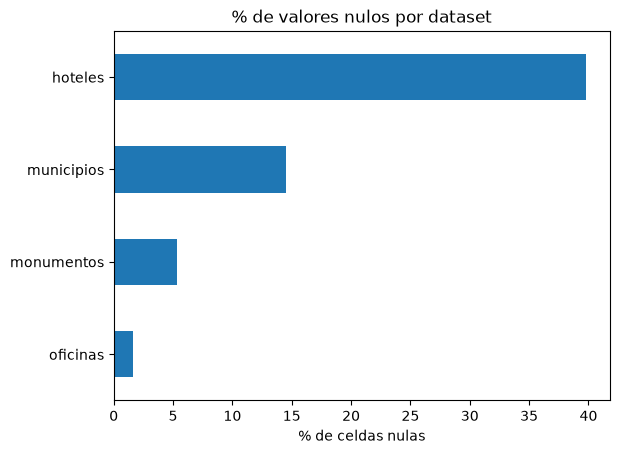

In [ ]:
datasets = {"municipios": municipios, "hoteles": hoteles, "monumentos": monumentos, "oficinas": oficinas}

resumen = pd.DataFrame({
    n: {"filas": df.shape[0],
        "columnas": df.shape[1],
        "% celdas nulas": round(df.isnull().mean().mean() * 100, 1),
        "duplicados": int(df.duplicated().sum()),
        "columnas 100% vacías": int(df.isnull().all().sum())}
    for n, df in datasets.items()
}).T.astype({"filas": int, "columnas": int, "duplicados": int, "columnas 100% vacías": int})
display(resumen)

resumen["% celdas nulas"].sort_values().plot.barh(title="% de valores nulos por dataset")
plt.xlabel("% de celdas nulas")
plt.show()

Las coordenadas de municipios vienen como texto con coma decimal (`-4,603775`). Para usarlas en un mapa hay que convertirlas a número:

In [ ]:
municipios[["Longitud", "Latitud"]].dtypes

Longitud    str
Latitud     str
dtype: object

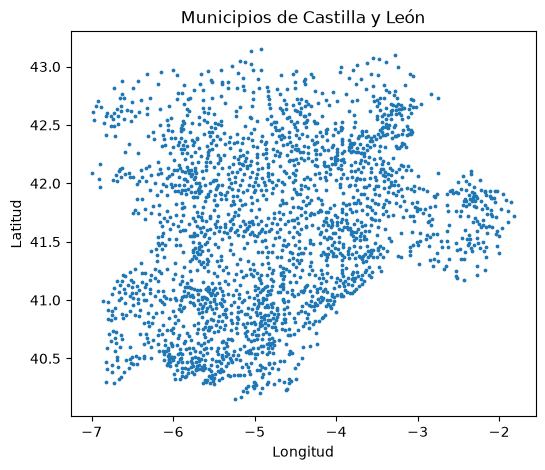

In [ ]:
lon = municipios["Longitud"].str.replace(",", ".").astype(float)
lat = municipios["Latitud"].str.replace(",", ".").astype(float)

plt.figure(figsize=(6, 5))
plt.scatter(lon, lat, s=3)
plt.title("Municipios de Castilla y León")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.show()

## Paso 9 · Conclusiones

### Resumen

| Dataset | Filas | Columnas | % celdas nulas | Duplicados | Columnas 100% vacías |
|---|---|---|---|---|---|
| Municipios | 2.248 | 13 | 14,5 % | 0 | 0 |
| Hoteles | 1.739 | 27 | 39,8 % | 0 | 4 |
| Monumentos | 1.378 | 18 | 5,3 % | 0 | 0 |
| Oficinas de turismo | 263 | 6 | 1,6 % | 0 | 0 |

### ¿Cuál tiene más valores nulos?
**Hoteles**, con casi un 40 % de celdas vacías:
- **4 columnas totalmente vacías**: `Codigo`, `Clase`, `Posada Real` y `Column 27` (esta última es una columna sobrante del CSV).
- **La mitad de los hoteles no tiene coordenadas**: faltan `GPS.Latitud` / `GPS.Longitud` en 894 de 1.739 (51 %).
- Datos de contacto incompletos: sin web 1.007 (58 %), sin email 637 (37 %); `Teléfono 2` y `Teléfono 3` casi vacíos.
- Sin dato de accesibilidad en 1.092 (63 %).

En **municipios** el 14,5 % es engañoso: casi todo viene de `Comarca` (solo rellena en los 38 municipios de El Bierzo) y de `Entidades_Locales_Menores`. No son datos perdidos: esos campos no aplican a la mayoría de municipios. Los datos importantes (código INE, población, coordenadas) están completos.

**Monumentos** está bastante completo (5,3 %). Los nulos se concentran en `calle` (492 sin dirección, 36 %), `identificadorBienInteresCultural` (266, 19 %), `clasificacion` (193, 14 %), `tipoConstruccion` y `periodoHistorico` (118 cada una, 9 %) y `codigoPostal` (104, 8 %). Lo esencial está completo: **todos los monumentos tienen coordenadas**, nombre y tipo, y solo 10 no tienen descripción.

**Oficinas** es el más limpio: solo 18 nulos en `Tipo`, 5 en `Ámbito` y 2 en `Establecimiento`.

### ¿Qué problemas aparecen?
- **Formato:** separador `;` y codificaciones distintas (municipios en latin-1, el resto en UTF-8).
- **Hoteles no es un dataset propio:** sale del Registro de Turismo, que mezcla 14 tipos de establecimiento (14.523 bares, 5.985 restaurantes…). Los hoteles son solo 1.739 de 35.930 registros (≈ 5 %).
- **Números guardados como texto:** las coordenadas de municipios usan coma decimal (`-4,603775`) y pandas las lee como texto; hay que convertirlas a número.
- **Código postal mal leído en monumentos:** pandas lo lee como número decimal (`5001.0`) y se pierde el cero inicial de Ávila (05) o Burgos (09). Hay que leerlo como texto (`dtype={"codigoPostal": str}`).
- **Nombres sin un formato común:** municipios está en MAYÚSCULAS (`ADANERO`) y hoteles no (`Salamanca`). Cada dataset llama distinto a la misma columna (`Municipio`, `poblacion_municipio`, `Localidad`). Para unirlos habrá que normalizar nombres (mayúsculas, tildes).
- **Columnas redundantes o sin valor:** en monumentos, `coordenadas` y `pto_geolocalizado` repiten latitud/longitud, y `poblacion` repite provincia/municipio/localidad. En oficinas, `Tipo` tiene un único valor (`Información`). En hoteles hay 4 columnas vacías.
- **Provincias inconsistentes en oficinas:** aparecen 10 valores distintos de provincia cuando Castilla y León tiene 9, así que alguna está escrita de dos formas.
- No hay filas duplicadas en ningún dataset.

### ¿Qué datos serán útiles para SmartTour?
- **Municipios:** es la tabla base. Tiene los 2.248 municipios con **código INE**, provincia, población y coordenadas completas.
- **Hoteles:** nombre, tipo (hotel, hostal…), categoría (estrellas), plazas, dirección, municipio, teléfono y coordenadas (cuando están).
- **Monumentos:** nombre, tipo de monumento, descripción, periodo histórico, clasificación (Bien de Interés Cultural), municipio y **coordenadas completas**. Es el dataset más preparado para mapas y rutas.
- **Oficinas de turismo:** qué localidades tienen oficina y de qué ámbito (municipal, provincial…).

### ¿Qué información falta?
- **Un código común:** solo municipios tiene código INE. Hoteles, monumentos y oficinas se tendrían que unir por nombre de municipio, que es menos fiable.
- **Coordenadas:** faltan en la mitad de los hoteles, y oficinas no tiene ninguna.
- **Oficinas:** solo 6 columnas. No hay dirección, teléfono, horario ni web.
- **Hoteles:** precios, valoraciones, ocupación y el contacto que falta.
- **Monumentos:** horarios de visita, precio de entrada, accesibilidad y fotos; además, un tercio no tiene dirección.
- **Afluencia de visitantes** y estacionalidad, que no están en ningún dataset.